Import the libraries and load the data

In [4]:

from pathlib import Path
%pip install pandas numpy matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
DATA_PATH = ROOT / "data" / "dataWA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(DATA_PATH)
df.head()


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


  Using cached pandas-3.0.6-cp313-cp313-win_amd64.whl.metadata (19 kB)
  Using cached numpy-2.5.4-cp313-cp313-win_amd64.whl.metadata (6.6 kB)
  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached tzdata-2026.5-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.66.1-cp313-cp313-win_amd64.whl.metadata (132 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached pandas-3.0.6-cp313-cp313-win_amd64.whl (9.6 MB)
Using cached numpy-2.5.4-cp313-cp313-win_amd64.whl (12.6 MB)
Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-n

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Inspect structure and quality

In [9]:
print("Shape:", df.shape)
display(df.dtypes.to_frame("data_type"))
display(df.isna().sum().to_frame("missing_values"))
print("Duplicate rows:", df.duplicated().sum())

blank_values = df.astype("str").apply(
    lambda col: col.str.strip().eq("").sum()
)

print("Columns with blank strings:")
print(blank_values[blank_values > 0])

Shape: (7043, 21)


,data_type
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


,missing_values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Duplicate rows: 0
Columns with blank strings:
TotalCharges    11
dtype: int64


Explore the Target Value

In [6]:
display(df["Churn"].value_counts(dropna=False))

churn_rate = (
    df["Churn"].eq("Yes").mean() * 100
)
print(f"Observed churn rate: {churn_rate:.2f}%")

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Observed churn rate: 26.54%


Compare the Contract Types

In [7]:
contract_churn = (
    df.groupby("Contract", dropna=False)["Churn"]
    .agg(
        customers="size",
        churn_rate=lambda s: s.eq("Yes").mean() * 100,
    )
    .sort_values("churn_rate", ascending=False)
)

display(contract_churn)

,customers,churn_rate
Contract,,
Month-to-month,3875,42.709677
One year,1473,11.269518
Two year,1695,2.831858


Plot the Relationship

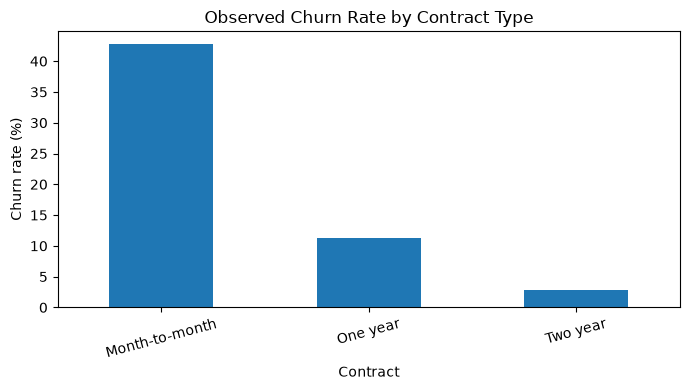

In [8]:
contract_churn["churn_rate"].plot(
    kind="bar",
    figsize=(7, 4),
    ylabel="Churn rate (%)",
    title="Observed Churn Rate by Contract Type",
    rot=15,
)
plt.tight_layout()
plt.show()